In [1]:

# CELL 1: Import libraries and load data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import geom
from scipy.special import xlogy
from pathlib import Path

OUTPUT = Path("geometric_outputs")
OUTPUT.mkdir(exist_ok=True)

df = pd.read_csv(
    "data/final_invoice_level.csv",
    parse_dates=["InvoiceDate"]
)

print("Dataset shape:", df.shape)
print("Unique customers:", df["CustomerID"].nunique())
print("First invoice:", df["InvoiceDate"].min())
print("Last invoice:", df["InvoiceDate"].max())

display(df.head())


Dataset shape: (36594, 13)
Unique customers: 5852
First invoice: 2009-12-01 07:45:00
Last invoice: 2011-12-09 12:50:00


,InvoiceYear,InvoiceNo,CustomerID,Country,InvoiceDate,InvoiceMonth,InvoiceAmount,ItemQuantity,ProductLineCount,DistinctProducts,PossibleDuplicateLineCount,HighInvoiceAmountFlag,InvoiceTimestampSpreadMinutes
0,2009,489434,13085,United Kingdom,2009-12-01 07:45:00,2009-12,505.30,166,8,8,0,False,0.0
1,2009,489435,13085,United Kingdom,2009-12-01 07:46:00,2009-12,145.80,60,4,4,0,False,0.0
2,2009,489436,13078,United Kingdom,2009-12-01 09:06:00,2009-12,630.33,193,19,19,0,False,0.0
3,2009,489437,15362,United Kingdom,2009-12-01 09:08:00,2009-12,310.75,145,23,23,0,False,0.0
4,2009,489438,18102,United Kingdom,2009-12-01 09:24:00,2009-12,2286.24,826,17,17,0,False,0.0


In [2]:

# CELL 2: Prepare unique customer purchasing days

# Use the last complete day as the observation cutoff
cutoff = (
    df["InvoiceDate"].max().normalize()
    - pd.Timedelta(days=1)
)

# Keep purchases occurring on or before the cutoff
daily = df[
    df["InvoiceDate"].dt.normalize() <= cutoff
][["CustomerID", "InvoiceDate"]].copy()

# Remove the time component
daily["PurchaseDay"] = daily["InvoiceDate"].dt.normalize()

# One record per customer per purchasing day
daily = (
    daily[["CustomerID", "PurchaseDay"]]
    .drop_duplicates()
    .sort_values(["CustomerID", "PurchaseDay"])
    .reset_index(drop=True)
)

# Number each customer's purchasing days
daily["PurchaseDayNumber"] = (
    daily.groupby("CustomerID").cumcount() + 1
)

print("Observation cutoff:", cutoff.date())
print("Unique customer-purchase days:", len(daily))
print("Customers:", daily["CustomerID"].nunique())

display(daily.head(10))


Observation cutoff: 2011-12-08
Unique customer-purchase days: 32843
Customers: 5851


,CustomerID,PurchaseDay,PurchaseDayNumber
0,12346,2010-03-02,1
1,12346,2010-06-28,2
2,12346,2011-01-18,3
3,12347,2010-10-31,1
4,12347,2010-12-07,2
5,12347,2011-01-26,3
6,12347,2011-04-07,4
7,12347,2011-06-09,5
8,12347,2011-08-02,6
9,12347,2011-10-31,7


In [3]:

# CELL 3: Construct first-repeat waiting times

# First observed purchasing day
first = daily[
    daily["PurchaseDayNumber"] == 1
][["CustomerID", "PurchaseDay"]].rename(
    columns={"PurchaseDay": "FirstDay"}
)

# Second distinct purchasing day
second = daily[
    daily["PurchaseDayNumber"] == 2
][["CustomerID", "PurchaseDay"]].rename(
    columns={"PurchaseDay": "SecondDay"}
)

# Keep customers even if they never returned
wait_df = first.merge(
    second,
    on="CustomerID",
    how="left"
)

# Event = 1 if the customer returned
# Event = 0 if no return was observed
wait_df["Event"] = (
    wait_df["SecondDay"].notna().astype(int)
)

# Available observation time after first purchase
wait_df["CensorDays"] = (
    cutoff - wait_df["FirstDay"]
).dt.days

# Days until next purchase, if observed
return_days = (
    wait_df["SecondDay"] - wait_df["FirstDay"]
).dt.days

# Use observed return time for returners,
# or available follow-up time for non-returners
wait_df["ObservedDays"] = np.where(
    wait_df["Event"] == 1,
    return_days,
    wait_df["CensorDays"]
)

# Remove customers with zero days of follow-up
wait_df = wait_df[
    wait_df["ObservedDays"] > 0
].copy()

wait_df["ObservedDays"] = (
    wait_df["ObservedDays"].astype(int)
)

print("Usable customers:", len(wait_df))
print("Observed returns:", wait_df["Event"].sum())
print("Right-censored customers:",
      (wait_df["Event"] == 0).sum())

display(wait_df.head(10))


Usable customers: 5848
Observed returns: 4177
Right-censored customers: 1671


,CustomerID,FirstDay,SecondDay,Event,CensorDays,ObservedDays
0,12346,2010-03-02,2010-06-28,1,646,118
1,12347,2010-10-31,2010-12-07,1,403,37
2,12348,2010-09-27,2010-12-16,1,437,80
3,12349,2010-04-29,2010-10-28,1,588,182
4,12350,2011-02-02,NaT,0,309,309
5,12351,2010-11-29,NaT,0,374,374
6,12352,2010-11-12,2010-11-29,1,391,17
7,12353,2010-10-27,2011-05-19,1,407,204
8,12354,2011-04-21,NaT,0,231,231
9,12355,2010-05-21,2011-05-09,1,566,353


In [4]:

# CELL 4: Descriptive analysis

returned = wait_df[
    wait_df["Event"] == 1
]["ObservedDays"]

total_customers = len(wait_df)
n_returns = int(wait_df["Event"].sum())
n_censored = total_customers - n_returns

print("Total customers:", total_customers)
print("Observed returns:", n_returns)
print("Censored customers:", n_censored)

print(
    "Observed return percentage:",
    round(100 * n_returns / total_customers, 2)
)

print("\nWaiting times of observed returners:")
print(returned.describe().round(2))

print("\nVariance of completed waiting times:",
      round(returned.var(), 2))

print(
    "Total observed customer-days:",
    wait_df["ObservedDays"].sum()
)


Total customers: 5848
Observed returns: 4177
Censored customers: 1671
Observed return percentage: 71.43

Waiting times of observed returners:
count    4177.00
mean      106.18
std       114.68
min         1.00
25%        28.00
50%        63.00
75%       141.00
max       714.00
Name: ObservedDays, dtype: float64

Variance of completed waiting times: 13152.51
Total observed customer-days: 1031215


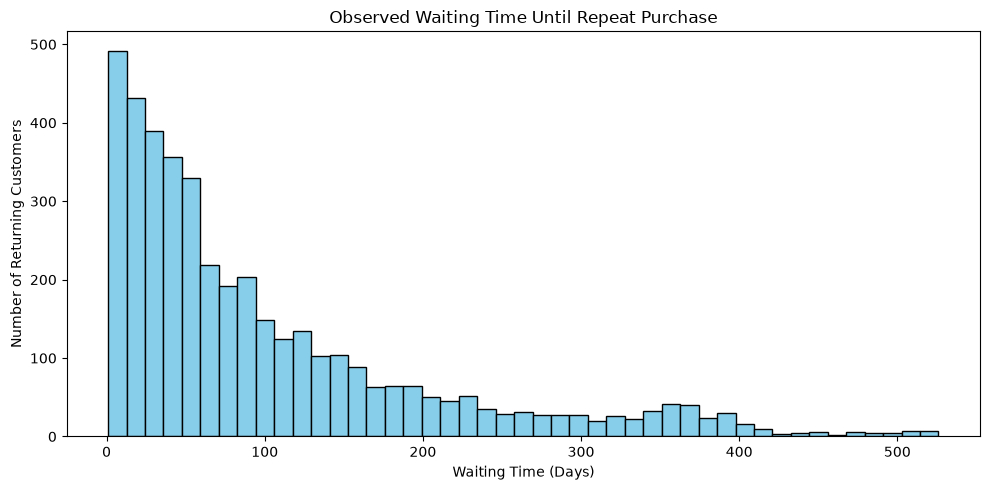

In [5]:

# CELL 5: Histogram of completed waiting times

plot_limit = returned.quantile(0.99)

plt.figure(figsize=(10, 5))

plt.hist(
    returned[returned <= plot_limit],
    bins=45,
    edgecolor="black",
    color="skyblue"
)

plt.title("Observed Waiting Time Until Repeat Purchase")
plt.xlabel("Waiting Time (Days)")
plt.ylabel("Number of Returning Customers")

plt.tight_layout()
plt.savefig(
    OUTPUT / "waiting_time_histogram.png",
    dpi=300
)
plt.show()


In [6]:

# CELL 6: Geometric MLE with right-censoring

t_obs = wait_df["ObservedDays"].to_numpy(dtype=int)
delta = wait_df["Event"].to_numpy(dtype=int)

# Number of observed returns
d = delta.sum()

# Total observed customer-days
R = t_obs.sum()

# Maximum likelihood estimate
p_hat = d / R

print("Observed returns (d):", d)
print("Total customer-days (R):", R)

print("\nGeometric MLE")
print("---------------------")
print("Estimated p:", round(p_hat, 6))
print("Daily return probability:",
      round(p_hat * 100, 4), "%")


Observed returns (d): 4177
Total customer-days (R): 1031215

Geometric MLE
---------------------
Estimated p: 0.004051
Daily return probability: 0.4051 %


In [7]:

# CELL 7: Theoretical quantities

geo_mean = geom.mean(p_hat)
geo_variance = geom.var(p_hat)
geo_std = geom.std(p_hat)

print("Theoretical mean:", round(geo_mean, 2))
print("Theoretical variance:", round(geo_variance, 2))
print("Standard deviation:", round(geo_std, 2))

print("\nProbability Calculations")
print("--------------------------")

# Exactly on day 15
print("P(T = 15):",
      round(geom.pmf(15, p_hat), 6))

# Within 7 days
print("P(T <= 7):",
      round(geom.cdf(7, p_hat), 6))

# Within 30 days
print("P(T <= 30):",
      round(geom.cdf(30, p_hat), 6))

# More than 30 days
print("P(T > 30):",
      round(geom.sf(30, p_hat), 6))


Theoretical mean: 246.88
Theoretical variance: 60702.53
Standard deviation: 246.38

Probability Calculations
--------------------------
P(T = 15): 0.003827
P(T <= 7): 0.028012
P(T <= 30): 0.114642
P(T > 30): 0.885358


**Theoretical quantities**

According to the fitted Geometric distribution, the expected waiting time before a repeat purchase is approximately 247 days.The high theoretical variance indicates substantial variability in modelled waiting times.The model estimates that approximately 11.46% of customers will make their next purchase within 30 days.However, the estimated mean waiting time differs considerably from the mean waiting time among observed returners (106.18 days). These two values cannot be compared directly because the observed-returner mean excludes censored waiting times.

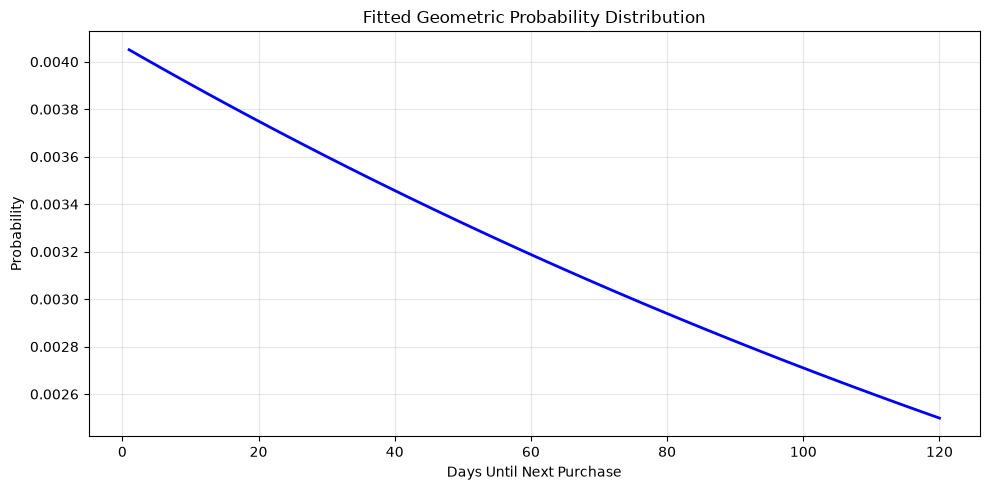

In [8]:

# CELL 8: Plot theoretical Geometric PMF

days = np.arange(1, 121)

probabilities = geom.pmf(days, p_hat)

plt.figure(figsize=(10, 5))

plt.plot(
    days,
    probabilities,
    color="blue",
    linewidth=2
)

plt.title("Fitted Geometric Probability Distribution")
plt.xlabel("Days Until Next Purchase")
plt.ylabel("Probability")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT / "geometric_pmf.png",
    dpi=300
)

plt.show()


In [9]:

# CELL 9: Kaplan-Meier empirical survival

max_day = int(t_obs.max())

day_grid = np.arange(1, max_day + 1)

# Number at risk on each day
at_risk = np.array([
    np.sum(t_obs >= day)
    for day in day_grid
])

# Number of observed returns on each day
event_counts = np.bincount(
    t_obs[delta == 1],
    minlength=max_day + 1
)[1:]

# Empirical daily return hazards
empirical_hazard = event_counts / at_risk

# Kaplan-Meier survival estimate
km_survival = np.cumprod(
    1 - empirical_hazard
)

# Geometric theoretical survival
geo_survival = geom.sf(day_grid, p_hat)

survival_table = pd.DataFrame({
    "Day": day_grid,
    "AtRisk": at_risk,
    "Events": event_counts,
    "EmpiricalHazard": empirical_hazard,
    "KMSurvival": km_survival,
    "GeometricSurvival": geo_survival
})

display(survival_table.head(10))


,Day,AtRisk,Events,EmpiricalHazard,KMSurvival,GeometricSurvival
0,1,5848,45,0.007695,0.992305,0.995949
1,2,5801,33,0.005689,0.986660,0.991915
2,3,5761,31,0.005381,0.981351,0.987897
3,4,5726,34,0.005938,0.975524,0.983896
4,5,5690,36,0.006327,0.969352,0.979911
5,6,5654,43,0.007605,0.961980,0.975941
6,7,5605,70,0.012489,0.949966,0.971988
7,8,5532,42,0.007592,0.942753,0.968051
8,9,5488,39,0.007106,0.936054,0.964130
9,10,5441,43,0.007903,0.928656,0.960225


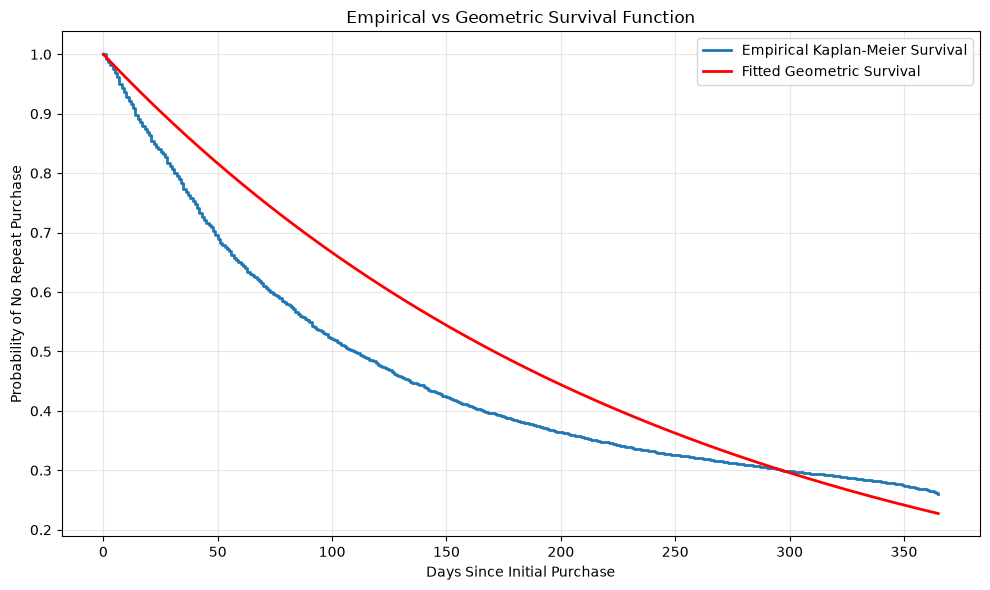

In [10]:

# CELL 10: Compare empirical and fitted survival

plot_days = min(365, max_day)

selected = survival_table[
    survival_table["Day"] <= plot_days
]

plt.figure(figsize=(10, 6))

plt.step(
    np.r_[0, selected["Day"].to_numpy()],
    np.r_[1, selected["KMSurvival"].to_numpy()],
    where="post",
    label="Empirical Kaplan-Meier Survival",
    linewidth=2
)

plt.plot(
    np.r_[0, selected["Day"].to_numpy()],
    np.r_[1, selected["GeometricSurvival"].to_numpy()],
    label="Fitted Geometric Survival",
    color="red",
    linewidth=2
)

plt.title("Empirical vs Geometric Survival Function")
plt.xlabel("Days Since Initial Purchase")
plt.ylabel("Probability of No Repeat Purchase")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT / "geometric_survival_comparison.png",
    dpi=300
)

plt.show()


In [11]:

# CELL 11: Return probability comparison

check_days = [7, 14, 30, 60, 90, 180]

comparison = survival_table[
    survival_table["Day"].isin(check_days)
].copy()

comparison["ObservedReturnProbability"] = (
    1 - comparison["KMSurvival"]
)

comparison["GeometricReturnProbability"] = (
    1 - comparison["GeometricSurvival"]
)

comparison["Difference"] = (
    comparison["ObservedReturnProbability"]
    - comparison["GeometricReturnProbability"]
)

display(
    comparison[[
        "Day",
        "ObservedReturnProbability",
        "GeometricReturnProbability",
        "Difference"
    ]].round(4)
)


,Day,ObservedReturnProbability,GeometricReturnProbability,Difference
6,7,0.0500,0.0280,0.0220
13,14,0.1024,0.0552,0.0471
29,30,0.1923,0.1146,0.0777
59,60,0.3523,0.2161,0.1362
89,90,0.4503,0.3060,0.1443
179,180,0.6151,0.5184,0.0968


,Interval,Returns,CustomerDays,EstimatedDailyHazard
0,1-7,292,40085,0.007285
1,8-30,821,116386,0.007054
2,31-90,1431,218998,0.006534
3,91-737,1633,655746,0.002490


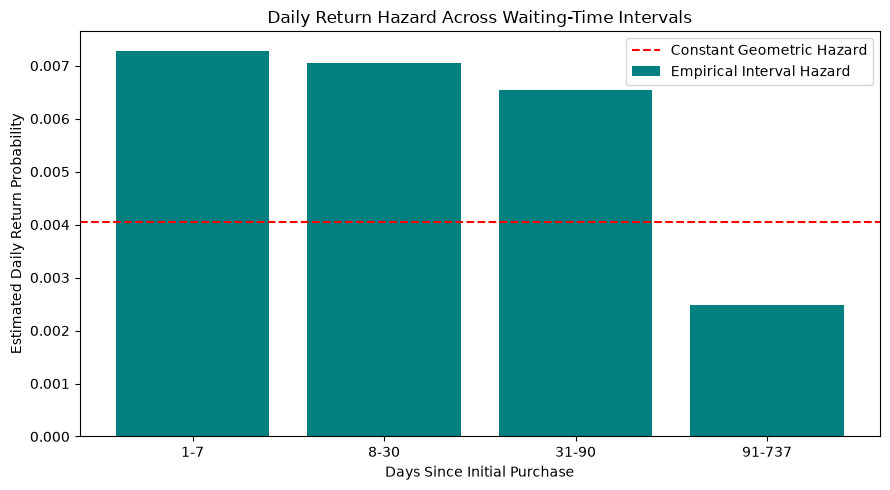

In [12]:

# CELL 12: Examine hazard variation

intervals = [
    (1, 7),
    (8, 30),
    (31, 90),
    (91, max_day)
]

hazard_results = []

for start, end in intervals:

    subset = survival_table[
        (survival_table["Day"] >= start) &
        (survival_table["Day"] <= end)
    ]

    total_exposure = subset["AtRisk"].sum()
    total_returns = subset["Events"].sum()

    estimated_hazard = (
        total_returns / total_exposure
        if total_exposure > 0 else np.nan
    )

    hazard_results.append({
        "Interval": f"{start}-{end}",
        "Returns": total_returns,
        "CustomerDays": total_exposure,
        "EstimatedDailyHazard": estimated_hazard
    })

hazard_table = pd.DataFrame(hazard_results)

display(hazard_table.round(6))

plt.figure(figsize=(9, 5))

plt.bar(
    hazard_table["Interval"],
    hazard_table["EstimatedDailyHazard"],
    color="teal",
    label="Empirical Interval Hazard"
)

plt.axhline(
    p_hat,
    color="red",
    linestyle="--",
    label="Constant Geometric Hazard"
)

plt.title("Daily Return Hazard Across Waiting-Time Intervals")
plt.xlabel("Days Since Initial Purchase")
plt.ylabel("Estimated Daily Return Probability")

plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT / "geometric_hazard_comparison.png",
    dpi=300
)

plt.show()


In [13]:

# CELL 13: Compare constant and two-phase hazard models

# Model 1: Constant Geometric probability
ll_geometric = (
    xlogy(d, p_hat)
    + xlogy(R - d, 1 - p_hat)
)

# Model 2: Separate hazards before and after day 30
threshold = 30

exposure_early = np.minimum(
    t_obs, threshold
).sum()

exposure_late = np.maximum(
    t_obs - threshold, 0
).sum()

events_early = np.sum(
    (delta == 1) & (t_obs <= threshold)
)

events_late = np.sum(
    (delta == 1) & (t_obs > threshold)
)

p_early = events_early / exposure_early
p_late = events_late / exposure_late

ll_two_phase = (
    xlogy(events_early, p_early)
    + xlogy(exposure_early - events_early, 1 - p_early)
    + xlogy(events_late, p_late)
    + xlogy(exposure_late - events_late, 1 - p_late)
)

n = len(wait_df)

# AIC and BIC
aic_geo = 2 * 1 - 2 * ll_geometric
bic_geo = np.log(n) - 2 * ll_geometric

aic_two = 2 * 2 - 2 * ll_two_phase
bic_two = 2 * np.log(n) - 2 * ll_two_phase

model_results = pd.DataFrame({
    "Model": [
        "Geometric - Constant Hazard",
        "Two-Phase Hazard Model"
    ],
    "Parameters": [1, 2],
    "AIC": [aic_geo, aic_two],
    "BIC": [bic_geo, bic_two]
})

print("Early daily return probability:",
      round(p_early, 6))

print("Late daily return probability:",
      round(p_late, 6))

display(model_results.round(2))


Early daily return probability: 0.007113
Late daily return probability: 0.003503


,Model,Parameters,AIC,BIC
0,Geometric - Constant Hazard,1,54360.41,54367.08
1,Two-Phase Hazard Model,2,53997.69,54011.04


Estimated p: 0.004051
95% Bootstrap CI:
0.003899 to 0.004222


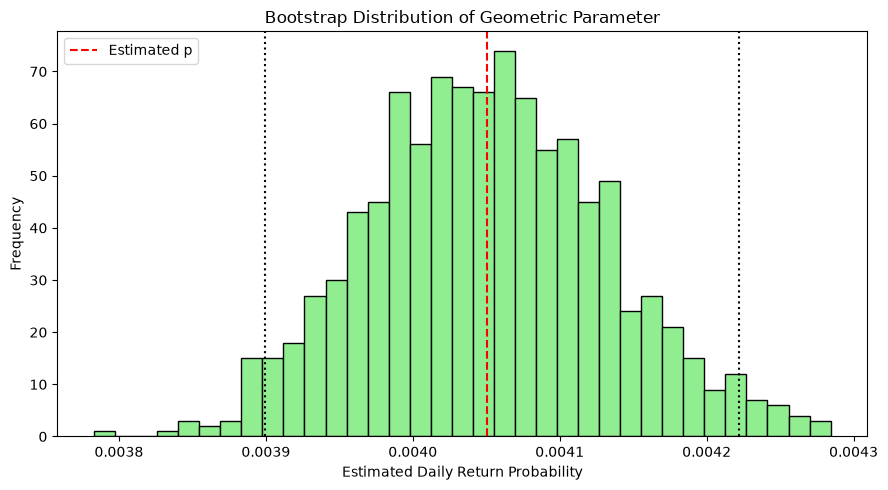

In [14]:

# CELL 14: Bootstrap confidence interval

rng = np.random.default_rng(42)

B = 1000
bootstrap_p = []

n_customers = len(wait_df)

for b in range(B):

    indices = rng.integers(
        0,
        n_customers,
        size=n_customers
    )

    sample_events = delta[indices]
    sample_days = t_obs[indices]

    p_boot = (
        sample_events.sum() / sample_days.sum()
    )

    bootstrap_p.append(p_boot)

bootstrap_p = np.array(bootstrap_p)

ci_lower, ci_upper = np.percentile(
    bootstrap_p,
    [2.5, 97.5]
)

print("Estimated p:", round(p_hat, 6))
print("95% Bootstrap CI:")
print(
    round(ci_lower, 6),
    "to",
    round(ci_upper, 6)
)

plt.figure(figsize=(9, 5))

plt.hist(
    bootstrap_p,
    bins=35,
    edgecolor="black",
    color="lightgreen"
)

plt.axvline(
    p_hat,
    color="red",
    linestyle="--",
    label="Estimated p"
)

plt.axvline(ci_lower, color="black", linestyle=":")
plt.axvline(ci_upper, color="black", linestyle=":")

plt.title("Bootstrap Distribution of Geometric Parameter")
plt.xlabel("Estimated Daily Return Probability")
plt.ylabel("Frequency")

plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT / "geometric_bootstrap.png",
    dpi=300
)

plt.show()


In [15]:

# CELL 15: Final Geometric model summary

final_summary = pd.DataFrame({
    "Metric": [
        "Number of Customers",
        "Observed Returns",
        "Censored Customers",
        "Total Customer-Days",
        "Geometric MLE (p)",
        "Expected Waiting Time",
        "Theoretical Variance",
        "P(Return within 7 days)",
        "P(Return within 30 days)",
        "Geometric AIC",
        "Geometric BIC",
        "Two-Phase AIC",
        "Two-Phase BIC",
        "Bootstrap CI Lower",
        "Bootstrap CI Upper"
    ],
    "Value": [
        len(wait_df),
        d,
        n_censored,
        R,
        p_hat,
        geo_mean,
        geo_variance,
        geom.cdf(7, p_hat),
        geom.cdf(30, p_hat),
        aic_geo,
        bic_geo,
        aic_two,
        bic_two,
        ci_lower,
        ci_upper
    ]
})

display(final_summary.round(6))

final_summary.to_csv(
    OUTPUT / "geometric_final_summary.csv",
    index=False
)

survival_table.to_csv(
    OUTPUT / "geometric_survival_table.csv",
    index=False
)

hazard_table.to_csv(
    OUTPUT / "geometric_hazard_table.csv",
    index=False
)

wait_df.to_csv(
    OUTPUT / "geometric_waiting_time_data.csv",
    index=False
)

print("All Geometric analysis results saved!")


,Metric,Value
0,Number of Customers,5.848000e+03
1,Observed Returns,4.177000e+03
2,Censored Customers,1.671000e+03
3,Total Customer-Days,1.031215e+06
4,Geometric MLE (p),4.051000e-03
5,Expected Waiting Time,2.468793e+02
6,Theoretical Variance,6.070253e+04
7,P(Return within 7 days),2.801200e-02
8,P(Return within 30 days),1.146420e-01
9,Geometric AIC,5.436041e+04


All Geometric analysis results saved!
